# 01 - Exploratory Data Analysis (EDA)

## Predicting Credit Card Fraud

### Objectives

- Understand the structure and quality of the dataset.
- Analyze the target variable and class imbalance.
- Explore numerical, categorical and boolean features.
- Investigate relationships between features and fraudulent transactions.
- Identify potential anomalies and data leakage.
- Compare train and test distributions.

### Dataset

Kaggle Playground Series - Season 6 Episode 11.

Target variable: `is_fraud`

In [3]:
import pandas as pd
import numpy as np
from pathlib import Path

# Dataset directory
DATA_DIR = Path("../data/raw")

# List available files
for file in DATA_DIR.iterdir():
    print(file.name)

# Load datasets
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

# Dataset dimensions
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Submission shape:", sample_submission.shape)

sample_submission.csv
test.csv
train.csv
Train shape: (699960, 26)
Test shape: (299984, 25)
Submission shape: (299984, 2)


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [6]:
# Dataset information
train.info()

# Data types distribution
display(
    train.dtypes.value_counts().to_frame("number_of_columns")
)

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-null  float64


,number_of_columns
int64,8
float64,7
bool,6
str,5


In [7]:
# General columns
TARGET = "is_fraud"
ID_COL = "id"

feature_cols = [
    col for col in train.columns
    if col not in [TARGET, ID_COL]
]

# Numerical features
numeric_cols = [
    col for col in train.select_dtypes(include="number").columns
    if col not in [TARGET, ID_COL]
]

# Categorical features
categorical_cols = train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

# Boolean features
boolean_cols = [
    col for col in feature_cols
    if pd.api.types.is_bool_dtype(train[col])
]

print("Numerical features:", len(numeric_cols))
print(numeric_cols)

print("\nCategorical features:", len(categorical_cols))
print(categorical_cols)

print("\nBoolean features:", len(boolean_cols))
print(boolean_cols)

# Check for unclassified features
classified = set(numeric_cols + categorical_cols + boolean_cols + [TARGET, ID_COL])

unclassified = set(train.columns) - classified

print("\nUnclassified columns:", unclassified)

Numerical features: 13
['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes']

Categorical features: 5
['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']

Boolean features: 6
['is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']

Unclassified columns: set()


In [8]:
# Missing values in train
train_missing = pd.DataFrame({
    "missing_count": train.isnull().sum(),
    "missing_percentage": train.isnull().mean() * 100
})

# Missing values in test
test_missing = pd.DataFrame({
    "missing_count": test.isnull().sum(),
    "missing_percentage": test.isnull().mean() * 100
})

# Combine results
missing_summary = train_missing.join(
    test_missing,
    lsuffix="_train",
    rsuffix="_test"
)

display(
    missing_summary.sort_values(
        "missing_percentage_train",
        ascending=False
    )
)

C:\Users\afern\AppData\Local\Temp\ipykernel_21708\4062327706.py:14: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  missing_summary = train_missing.join(


,missing_count_train,missing_percentage_train,missing_count_test,missing_percentage_test
id,0,0.0000,0.0000,0.0000
amount_usd,0,0.0000,0.0000,0.0000
hours_since_last_txn,0,0.0000,0.0000,0.0000
txn_count_last_24h,0,0.0000,0.0000,0.0000
distance_from_home_km,0,0.0000,0.0000,0.0000
card_age_months,0,0.0000,0.0000,0.0000
customer_age,0,0.0000,0.0000,0.0000
account_balance_usd,0,0.0000,0.0000,0.0000
cvv_retry_count,0,0.0000,0.0000,0.0000
velocity_score,0,0.0000,0.0000,0.0000


In [9]:
print("Train duplicated rows:", train.duplicated().sum())
print("Test duplicated rows:", test.duplicated().sum())

print("\nTrain duplicated IDs:", train["id"].duplicated().sum())
print("Test duplicated IDs:", test["id"].duplicated().sum())

# IDs shared between train and test
shared_ids = train["id"].isin(test["id"]).sum()

print("\nIDs shared between train and test:", shared_ids)

# Duplicates considering only predictors (excluding ID and target)
print(
    "\nDuplicated feature rows in train:",
    train.duplicated(subset=feature_cols).sum()
)

print(
    "Duplicated feature rows in test:",
    test.duplicated(subset=feature_cols).sum()
)

Train duplicated rows: 0
Test duplicated rows: 0

Train duplicated IDs: 0
Test duplicated IDs: 0

IDs shared between train and test: 0

Duplicated feature rows in train: 0
Duplicated feature rows in test: 0


In [10]:
# Target value counts
target_counts = train[TARGET].value_counts(dropna=False).sort_index()

target_percentages = (
    train[TARGET].value_counts(normalize=True, dropna=False).sort_index() * 100
)

target_summary = pd.DataFrame({
    "transactions": target_counts,
    "percentage": target_percentages
})

display(target_summary)

,transactions,percentage
is_fraud,,
0.0000,688271,98.3300
1.0000,11689,1.6700


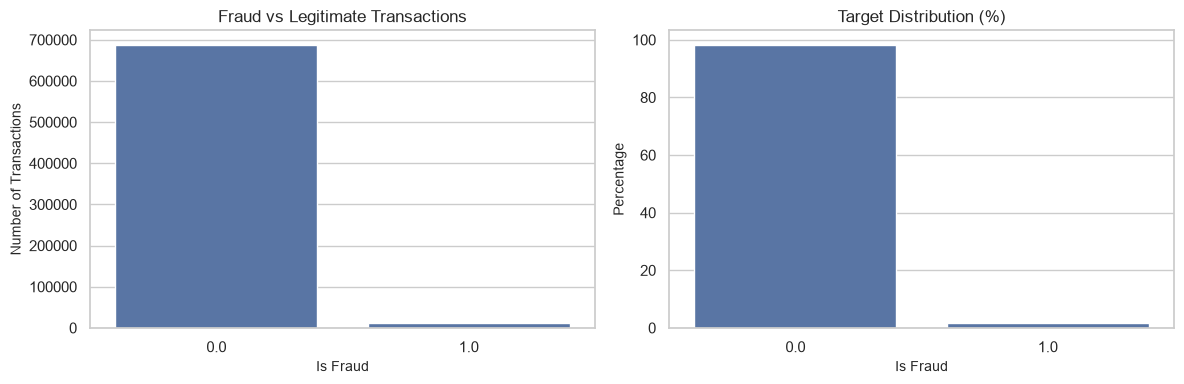

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Absolute counts
sns.barplot(
    x=target_counts.index.astype(str),
    y=target_counts.values,
    ax=axes[0]
)

axes[0].set_title("Fraud vs Legitimate Transactions")
axes[0].set_xlabel("Is Fraud")
axes[0].set_ylabel("Number of Transactions")

# Percentages
sns.barplot(
    x=target_percentages.index.astype(str),
    y=target_percentages.values,
    ax=axes[1]
)

axes[1].set_title("Target Distribution (%)")
axes[1].set_xlabel("Is Fraud")
axes[1].set_ylabel("Percentage")

plt.tight_layout()
plt.show()

In [12]:
class_counts = train[TARGET].value_counts()

majority_class = class_counts.max()
minority_class = class_counts.min()

imbalance_ratio = majority_class / minority_class

majority_baseline = majority_class / class_counts.sum()

fraud_percentage = (
    train[TARGET].mean() * 100
)

print(f"Fraud percentage: {fraud_percentage:.4f}%")
print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")
print(f"Majority class baseline accuracy: {majority_baseline:.4%}")

Fraud percentage: 1.6700%
Imbalance ratio: 58.88:1
Majority class baseline accuracy: 98.3300%


In [13]:
numeric_summary = train[numeric_cols].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

numeric_summary["skewness"] = train[numeric_cols].skew()

display(numeric_summary)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skewness
amount_usd,"699,960.0000",79.8931,205.1735,1.0000,4.4200,6.8600,15.8100,27.2500,43.1100,542.4600,936.9500,"6,872.6900",7.0022
hours_since_last_txn,"699,960.0000",6.6337,6.2901,0.0100,0.1100,0.4700,2.1100,4.7300,9.1900,19.4000,29.3800,51.9800,1.8232
txn_count_last_24h,"699,960.0000",2.9841,1.4990,0.0000,0.0000,1.0000,2.0000,3.0000,4.0000,6.0000,7.0000,11.0000,0.4364
distance_from_home_km,"699,960.0000",13.5876,11.6173,0.0000,0.0800,0.7600,4.4300,10.2200,19.7500,37.9400,47.8600,57.9300,1.0597
card_age_months,"699,960.0000",46.8630,5.5792,25.0000,34.0000,38.0000,43.0000,47.0000,51.0000,56.0000,60.0000,73.0000,0.1330
customer_age,"699,960.0000",51.4303,17.8991,18.0000,19.0000,21.0000,38.0000,52.0000,66.0000,79.0000,81.0000,81.0000,-0.1408
account_balance_usd,"699,960.0000","2,064.9981","3,400.1329",58.2500,454.8500,532.6100,834.1200,"1,382.7400","2,517.0200","4,861.1800","9,082.8100","99,701.3900",14.4362
cvv_retry_count,"699,960.0000",0.0855,0.2895,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,3.0000,3.3187
velocity_score,"699,960.0000",18.9294,10.8644,0.0000,0.0000,0.0000,11.4000,18.6000,26.0000,37.4000,46.1000,72.9000,0.2597
time_of_day_hour,"699,960.0000",11.7619,6.8692,0.0000,0.0000,1.0000,6.0000,12.0000,18.0000,22.0000,23.0000,23.0000,-0.0561


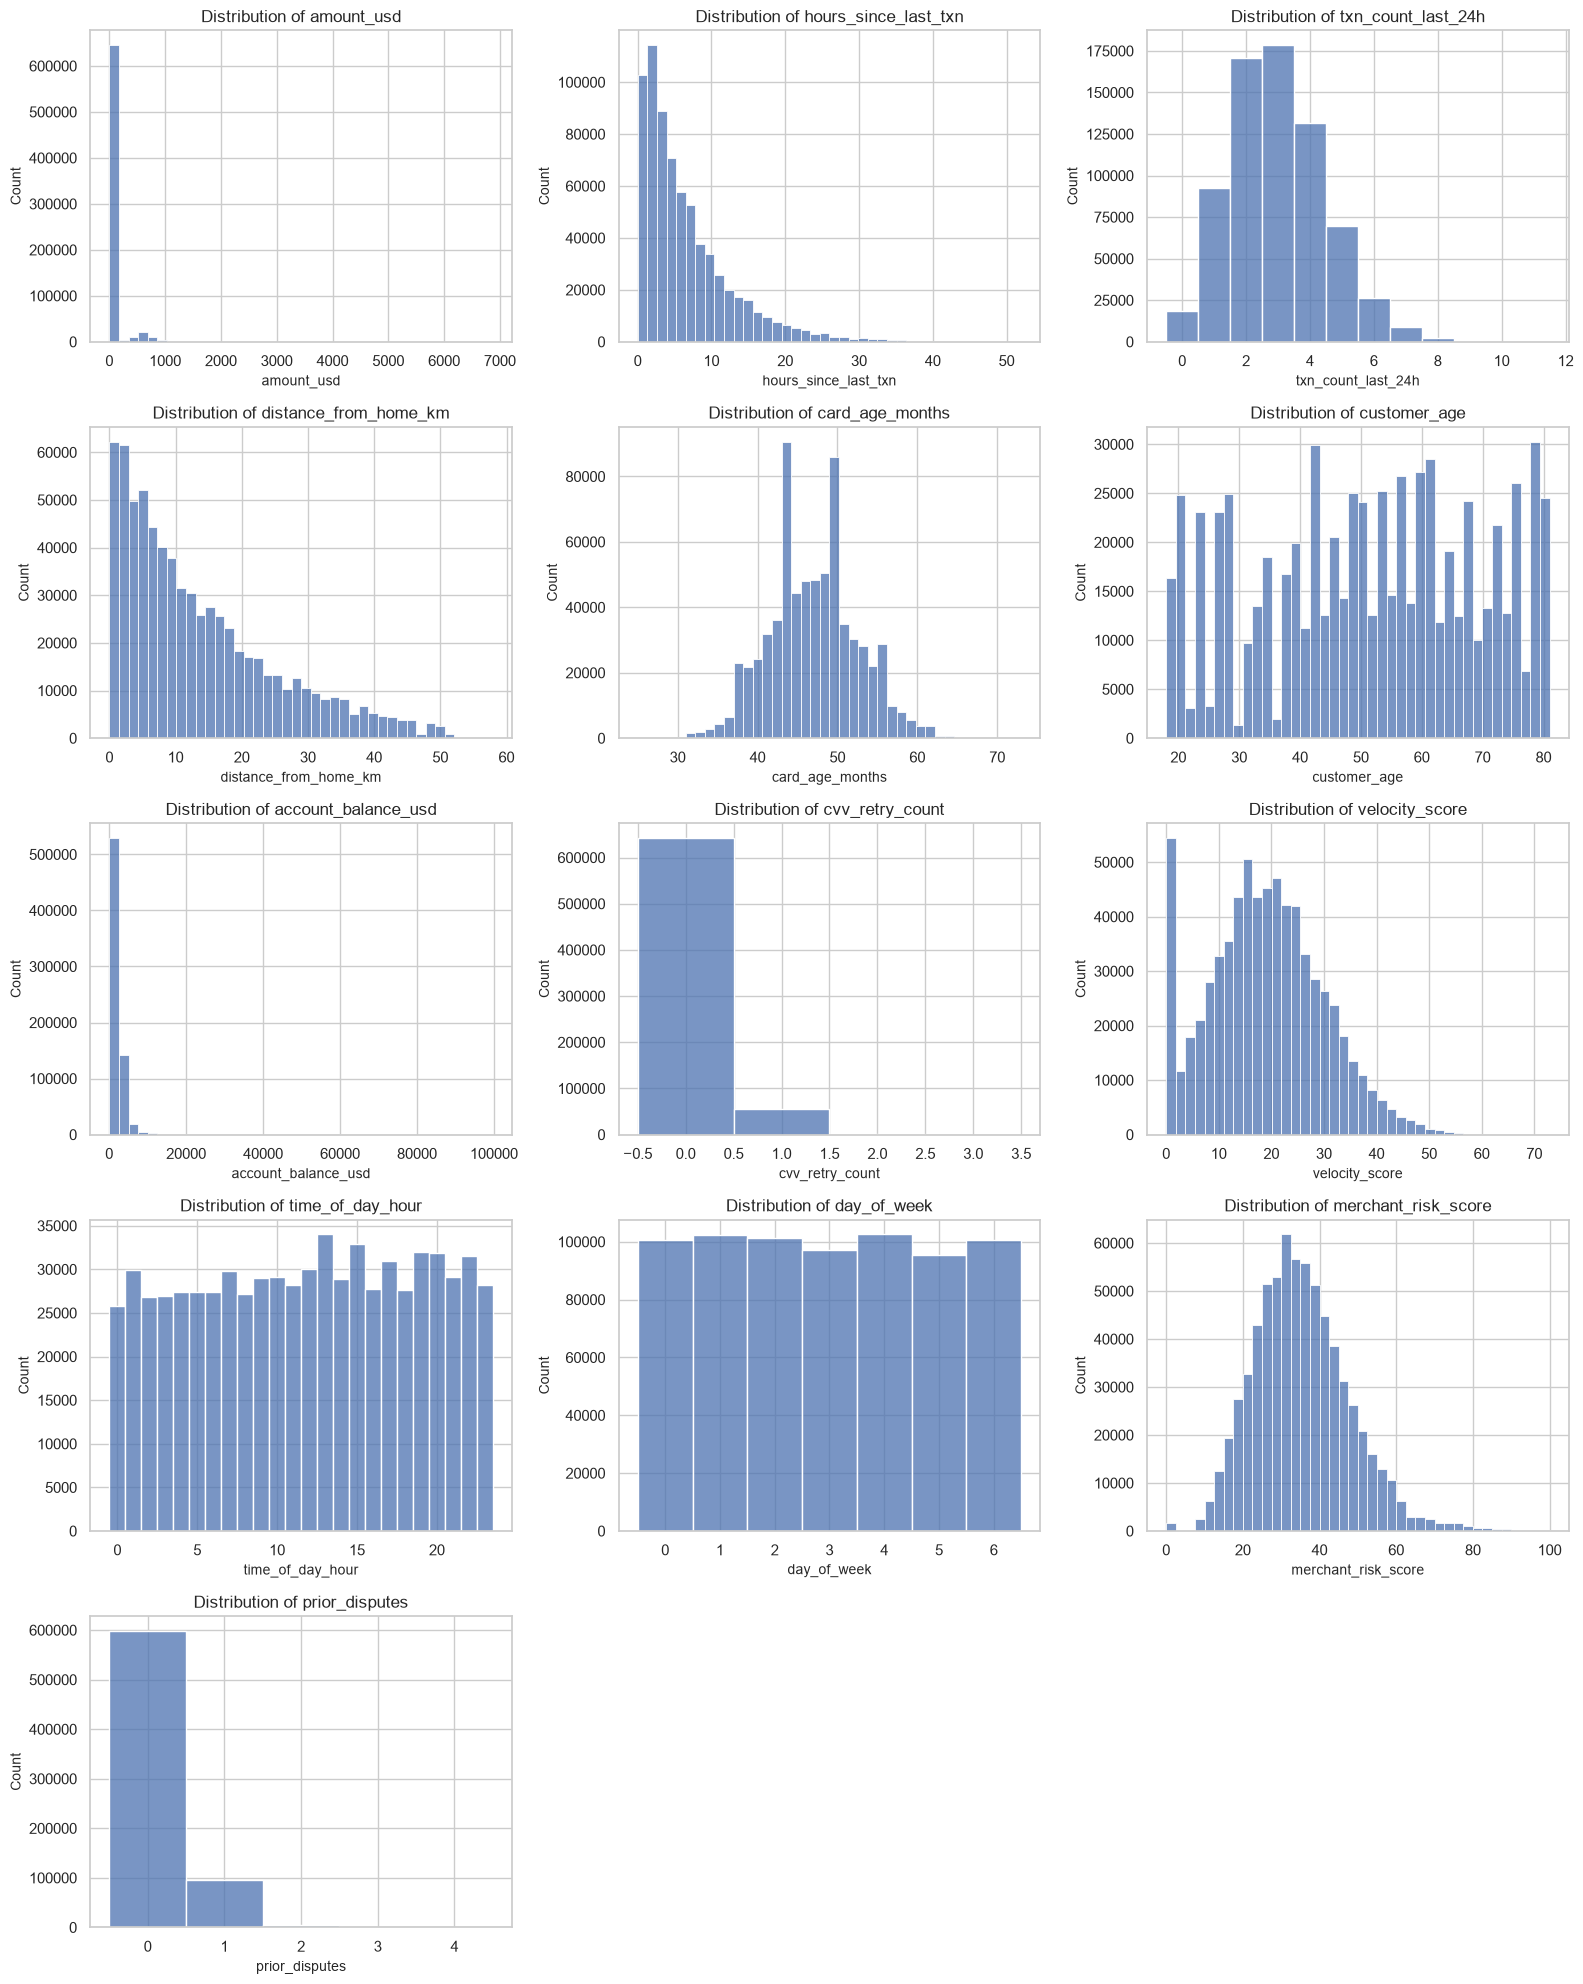

In [14]:
n_cols = 3
n_rows = int(np.ceil(len(numeric_cols) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, n_rows * 4)
)

axes = np.array(axes).flatten()

discrete_features = [
    "time_of_day_hour",
    "day_of_week",
    "txn_count_last_24h",
    "cvv_retry_count",
    "prior_disputes"
]

for i, col in enumerate(numeric_cols):

    sns.histplot(
        data=train,
        x=col,
        bins=40,
        discrete=col in discrete_features,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {col}")

# Remove unused plots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [15]:
outlier_results = []

for col in numeric_cols:

    q1 = train[col].quantile(0.25)
    q3 = train[col].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (train[col] < lower_bound) |
        (train[col] > upper_bound)
    ).sum()

    outlier_results.append({
        "feature": col,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outliers": outliers,
        "outlier_percentage": outliers / train[col].notna().sum() * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

display(
    outlier_summary.sort_values(
        "outlier_percentage",
        ascending=False
    )
)

,feature,lower_bound,upper_bound,outliers,outlier_percentage
12,prior_disputes,0.0000,0.0000,101564,14.5100
0,amount_usd,-25.1400,84.0600,70741,10.1064
7,cvv_retry_count,0.0000,0.0000,57872,8.2679
1,hours_since_last_txn,-8.5100,19.8100,32816,4.6883
6,account_balance_usd,"-1,690.2300","5,041.3700",29068,4.1528
3,distance_from_home_km,-18.5500,42.7300,16770,2.3959
11,merchant_risk_score,1.9500,67.1500,13028,1.8612
8,velocity_score,-10.5000,47.9000,4276,0.6109
2,txn_count_last_24h,-1.0000,7.0000,2704,0.3863
4,card_age_months,31.0000,63.0000,2253,0.3219


In [16]:
categorical_summary = []

for col in categorical_cols:

    categorical_summary.append({
        "feature": col,
        "unique_values": train[col].nunique(dropna=False),
        "most_frequent": train[col].mode().iloc[0],
        "most_frequent_count": train[col].value_counts(dropna=False).iloc[0]
    })

categorical_summary = pd.DataFrame(categorical_summary)

display(categorical_summary)

,feature,unique_values,most_frequent,most_frequent_count
0,merchant_category,12,Online Retail,155097
1,card_type,5,Visa,345001
2,auth_method,5,3D Secure,210036
3,channel,5,Online,273939
4,device_type,8,Android Phone,237454


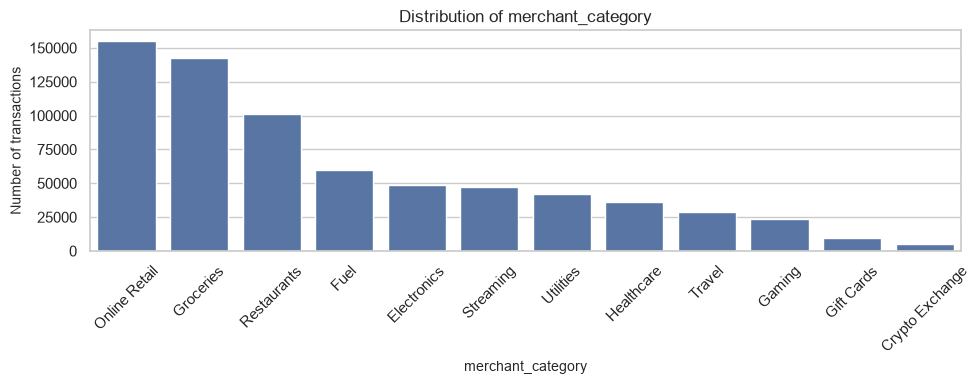

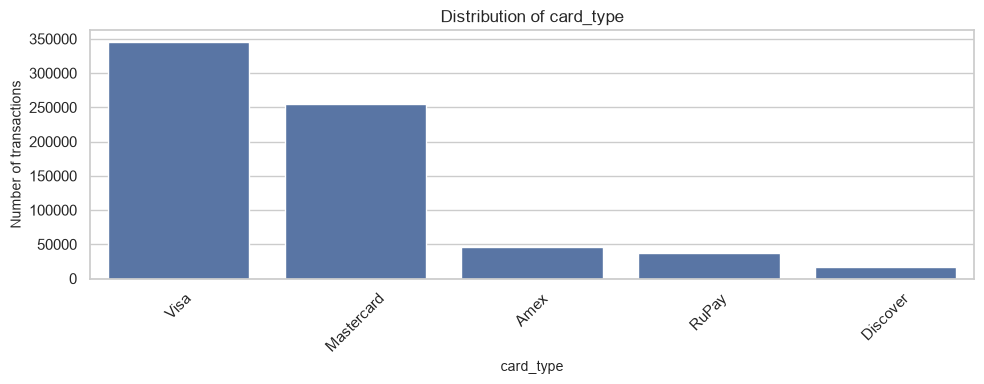

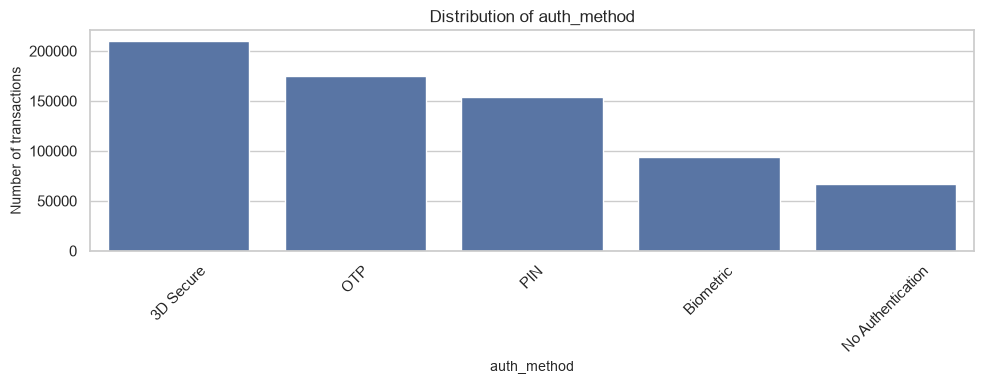

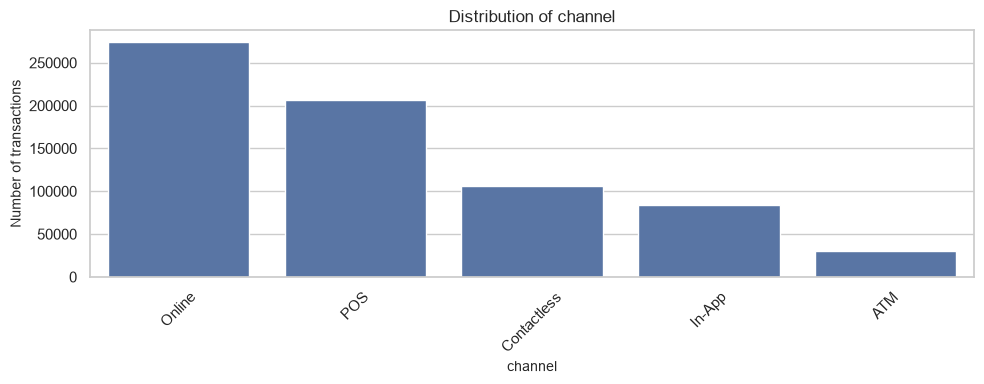

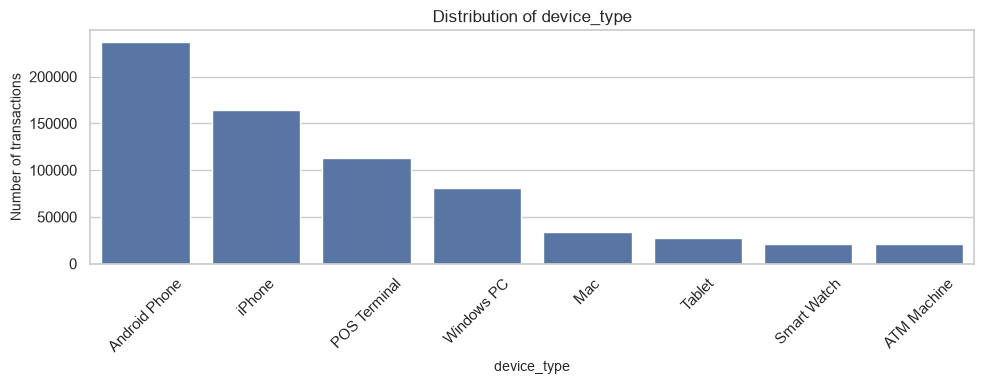

In [17]:
for col in categorical_cols:

    plt.figure(figsize=(10, 4))

    order = train[col].value_counts().index

    sns.countplot(
        data=train,
        x=col,
        order=order
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of transactions")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

In [18]:
for col in boolean_cols:

    counts = train[col].value_counts(dropna=False)

    percentages = train[col].value_counts(
        normalize=True,
        dropna=False
    ) * 100

    summary = pd.DataFrame({
        "count": counts,
        "percentage": percentages
    })

    print(f"\n{col}")
    display(summary)


is_foreign_transaction


,count,percentage
is_foreign_transaction,,
False,687862,98.2716
True,12098,1.7284



is_new_merchant


,count,percentage
is_new_merchant,,
False,593240,84.7534
True,106720,15.2466



used_vpn


,count,percentage
used_vpn,,
False,676295,96.6191
True,23665,3.3809


... (2 outputs left out)


billing_shipping_mismatch


,count,percentage
billing_shipping_mismatch,,
False,690906,98.7065
True,9054,1.2935



is_ai_generated_scam_attempt


,count,percentage
is_ai_generated_scam_attempt,,
False,697661,99.6716
True,2299,0.3284


In [19]:
# Pearson correlation
pearson_corr = train[numeric_cols + [TARGET]].corr(
    method="pearson"
)[TARGET].drop(TARGET)

# Spearman correlation
spearman_corr = train[numeric_cols + [TARGET]].corr(
    method="spearman"
)[TARGET].drop(TARGET)

correlation_summary = pd.DataFrame({
    "pearson": pearson_corr,
    "spearman": spearman_corr
})

correlation_summary["abs_pearson"] = (
    correlation_summary["pearson"].abs()
)

display(
    correlation_summary.sort_values(
        "abs_pearson",
        ascending=False
    )
)

,pearson,spearman,abs_pearson
cvv_retry_count,0.2123,0.1936,0.2123
merchant_risk_score,0.1254,0.1105,0.1254
velocity_score,0.1016,0.0936,0.1016
txn_count_last_24h,0.0580,0.0545,0.0580
customer_age,0.0561,0.0554,0.0561
prior_disputes,0.0236,0.0234,0.0236
hours_since_last_txn,-0.0205,-0.0303,0.0205
amount_usd,0.0194,0.0199,0.0194
day_of_week,0.0037,0.0036,0.0037
distance_from_home_km,0.0018,0.0017,0.0018


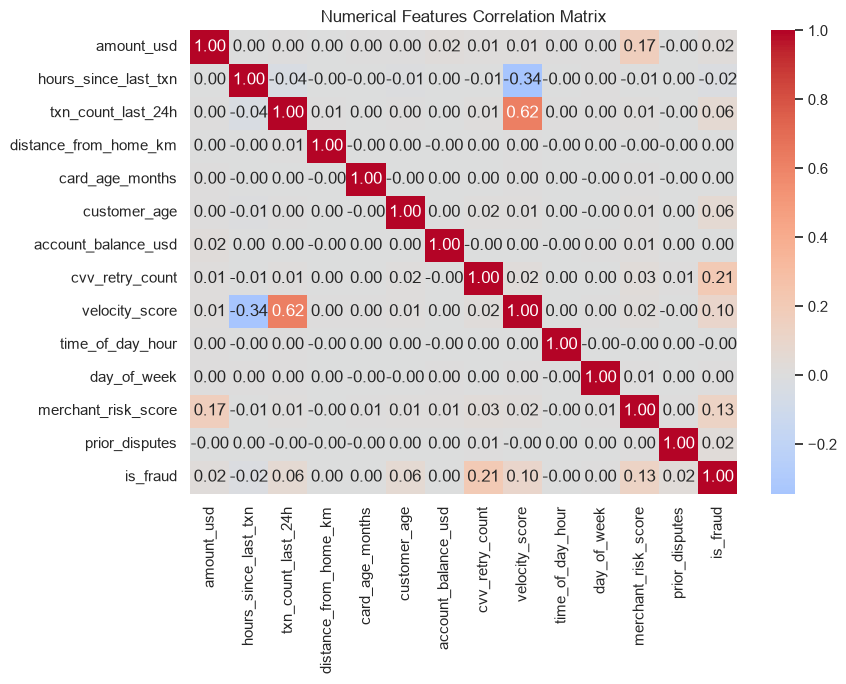

In [20]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    train[numeric_cols + [TARGET]].corr(method="pearson"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Numerical Features Correlation Matrix")
plt.tight_layout()
plt.show()

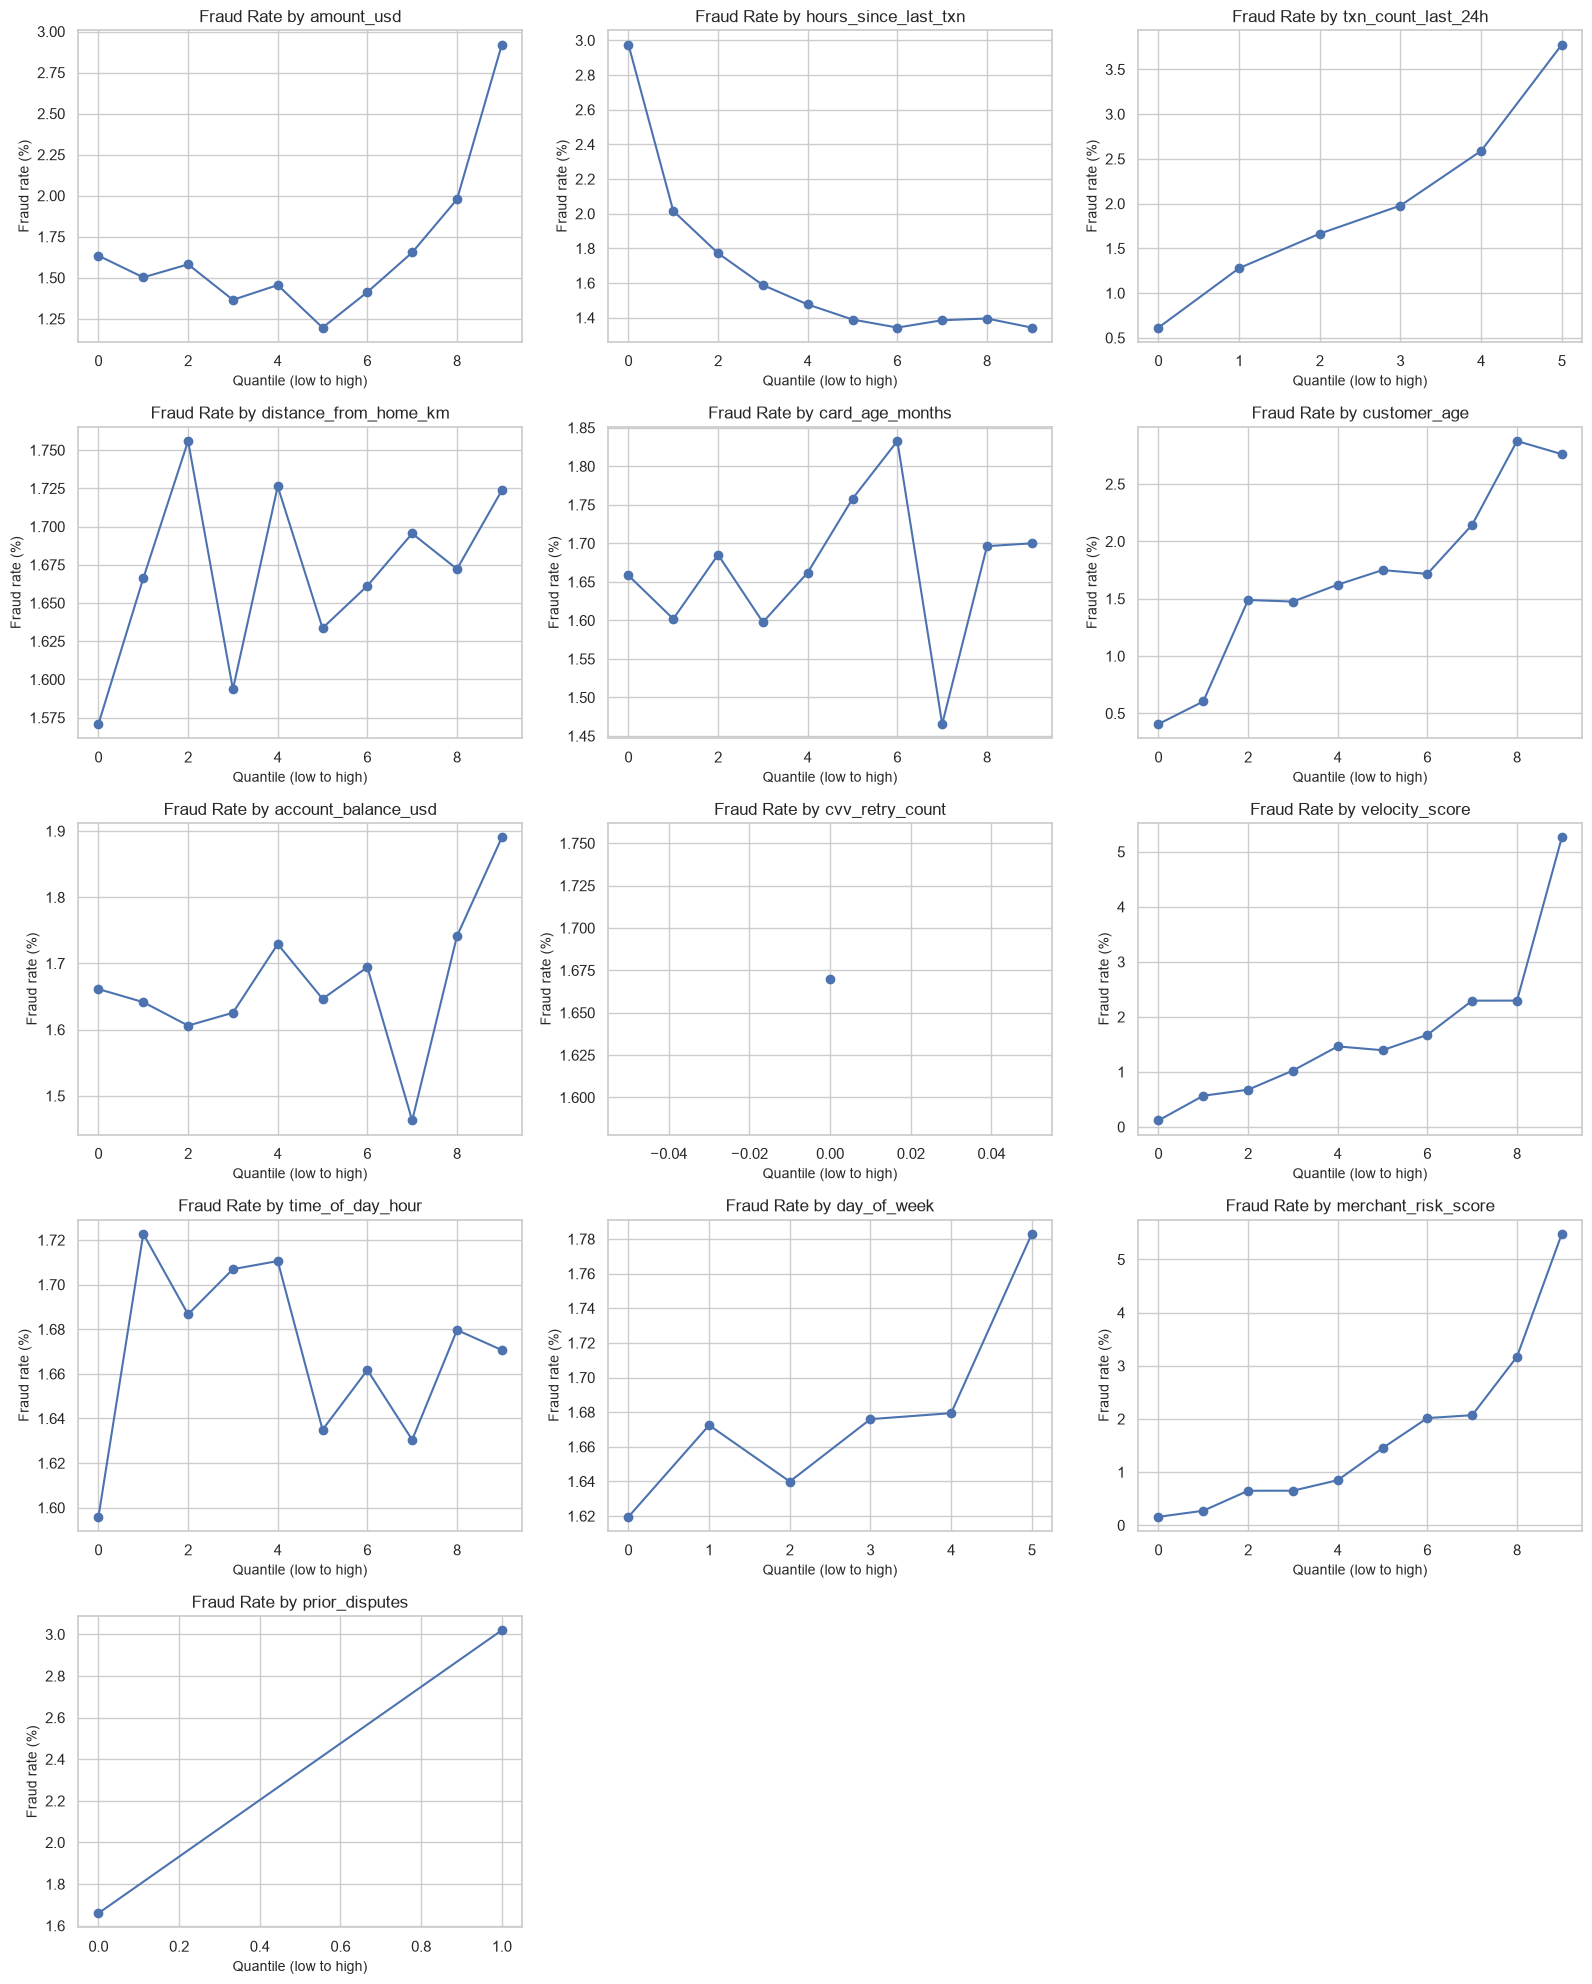

In [21]:
n_cols = 3
n_rows = int(np.ceil(len(numeric_cols) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, n_rows * 4)
)

axes = np.array(axes).flatten()

for i, col in enumerate(numeric_cols):

    temp = train[[col, TARGET]].dropna().copy()

    temp["quantile"] = pd.qcut(
        temp[col],
        q=10,
        labels=False,
        duplicates="drop"
    )

    fraud_rate = (
        temp.groupby("quantile", observed=True)[TARGET]
        .mean() * 100
    )

    axes[i].plot(
        fraud_rate.index,
        fraud_rate.values,
        marker="o"
    )

    axes[i].set_title(f"Fraud Rate by {col}")
    axes[i].set_xlabel("Quantile (low to high)")
    axes[i].set_ylabel("Fraud rate (%)")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [22]:
for col in categorical_cols:

    fraud_analysis = (
        train.groupby(col, dropna=False)[TARGET]
        .agg(
            transactions="size",
            frauds="sum",
            fraud_rate="mean"
        )
        .sort_values("fraud_rate", ascending=False)
    )

    fraud_analysis["fraud_rate"] *= 100

    print(f"\nFraud analysis by {col}")

    display(fraud_analysis)


Fraud analysis by merchant_category


,transactions,frauds,fraud_rate
merchant_category,,,
Gift Cards,9456,690.0000,7.2970
Crypto Exchange,5285,345.0000,6.5279
Gaming,23784,"1,311.0000",5.5121
Electronics,48693,"1,501.0000",3.0826
Streaming,47196,"1,061.0000",2.2481
Travel,28715,534.0000,1.8597
Utilities,42027,581.0000,1.3824
Healthcare,35889,462.0000,1.2873
Fuel,59880,741.0000,1.2375



Fraud analysis by card_type


,transactions,frauds,fraud_rate
card_type,,,
Amex,45797,871.0000,1.9019
Visa,345001,"5,860.0000",1.6985
RuPay,37070,623.0000,1.6806
Mastercard,254857,"4,084.0000",1.6025
Discover,17235,251.0000,1.4563



Fraud analysis by auth_method


,transactions,frauds,fraud_rate
auth_method,,,
No Authentication,67060,"4,322.0000",6.4450
3D Secure,210036,"3,098.0000",1.4750
OTP,175178,"2,464.0000",1.4066
PIN,154020,"1,337.0000",0.8681
Biometric,93666,468.0000,0.4996



Fraud analysis by channel


,transactions,frauds,fraud_rate
channel,,,
Online,273939,"4,773.0000",1.7424
POS,206465,"3,428.0000",1.6603
In-App,83716,"1,367.0000",1.6329
ATM,30220,480.0000,1.5884
Contactless,105620,"1,641.0000",1.5537



Fraud analysis by device_type


,transactions,frauds,fraud_rate
device_type,,,
POS Terminal,113237,"1,958.0000",1.7291
iPhone,164691,"2,836.0000",1.7220
Mac,33973,581.0000,1.7102
Tablet,27688,471.0000,1.7011
Smart Watch,21106,359.0000,1.7009
ATM Machine,20877,354.0000,1.6956
Windows PC,80934,"1,306.0000",1.6137
Android Phone,237454,"3,824.0000",1.6104


In [23]:
for col in boolean_cols:

    fraud_analysis = (
        train.groupby(col, dropna=False)[TARGET]
        .agg(
            transactions="size",
            frauds="sum",
            fraud_rate="mean"
        )
        .sort_values("fraud_rate", ascending=False)
    )

    fraud_analysis["fraud_rate"] *= 100

    print(f"\nFraud analysis by {col}")

    display(fraud_analysis)


Fraud analysis by is_foreign_transaction


,transactions,frauds,fraud_rate
is_foreign_transaction,,,
True,12098,"1,521.0000",12.5723
False,687862,"10,168.0000",1.4782



Fraud analysis by is_new_merchant


,transactions,frauds,fraud_rate
is_new_merchant,,,
True,106720,"5,052.0000",4.7339
False,593240,"6,637.0000",1.1188



Fraud analysis by used_vpn


,transactions,frauds,fraud_rate
used_vpn,,,
True,23665,"1,550.0000",6.5498
False,676295,"10,139.0000",1.4992


... (2 outputs left out)


Fraud analysis by billing_shipping_mismatch


,transactions,frauds,fraud_rate
billing_shipping_mismatch,,,
True,9054,"1,176.0000",12.9887
False,690906,"10,513.0000",1.5216



Fraud analysis by is_ai_generated_scam_attempt


,transactions,frauds,fraud_rate
is_ai_generated_scam_attempt,,,
True,2299,350.0000,15.2240
False,697661,"11,339.0000",1.6253


In [24]:
print("TRAIN ID")
print("Minimum:", train["id"].min())
print("Maximum:", train["id"].max())
print("Unique:", train["id"].nunique())
print("Monotonic increasing:", train["id"].is_monotonic_increasing)

print("\nTEST ID")
print("Minimum:", test["id"].min())
print("Maximum:", test["id"].max())
print("Unique:", test["id"].nunique())

print("\nID correlation with target:")
print(train["id"].corr(train[TARGET]))

TRAIN ID
Minimum: 0
Maximum: 699959
Unique: 699960
Monotonic increasing: True

TEST ID
Minimum: 699960
Maximum: 999943
Unique: 299984

ID correlation with target:
-0.0006443353134705076


,transactions,fraud_rate
id_decile,,
0,69996,1.6701
1,69996,1.5872
2,69996,1.7115
3,69996,1.7344
4,69996,1.7130
5,69996,1.6858
6,69996,1.6730
7,69996,1.6258
8,69996,1.6958


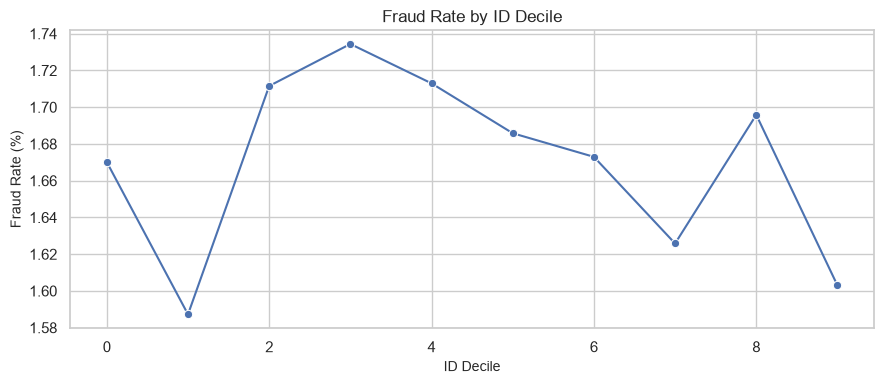

In [25]:
id_analysis = train[["id", TARGET]].copy()

id_analysis["id_decile"] = pd.qcut(
    id_analysis["id"],
    q=10,
    labels=False,
    duplicates="drop"
)

id_fraud_rate = (
    id_analysis.groupby("id_decile")[TARGET]
    .agg(
        transactions="size",
        fraud_rate="mean"
    )
)

id_fraud_rate["fraud_rate"] *= 100

display(id_fraud_rate)

plt.figure(figsize=(9, 4))

sns.lineplot(
    data=id_fraud_rate,
    x=id_fraud_rate.index,
    y="fraud_rate",
    marker="o"
)

plt.title("Fraud Rate by ID Decile")
plt.xlabel("ID Decile")
plt.ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.show()

In [26]:
train_stats = train[numeric_cols].agg(
    ["mean", "std", "median"]
).T

test_stats = test[numeric_cols].agg(
    ["mean", "std", "median"]
).T

comparison = pd.DataFrame({
    "train_mean": train_stats["mean"],
    "test_mean": test_stats["mean"],
    "train_std": train_stats["std"],
    "test_std": test_stats["std"],
    "train_median": train_stats["median"],
    "test_median": test_stats["median"]
})

# Standardized Mean Difference
pooled_std = np.sqrt(
    (comparison["train_std"] ** 2 +
     comparison["test_std"] ** 2) / 2
)

comparison["standardized_mean_diff"] = (
    (comparison["test_mean"] - comparison["train_mean"]) /
    pooled_std.replace(0, np.nan)
)

comparison["abs_smd"] = comparison[
    "standardized_mean_diff"
].abs()

display(
    comparison.sort_values(
        "abs_smd",
        ascending=False
    )
)

,train_mean,test_mean,train_std,test_std,train_median,test_median,standardized_mean_diff,abs_smd
day_of_week,2.9817,2.9713,2.0017,1.9972,3.0000,3.0000,-0.0052,0.0052
card_age_months,46.8630,46.8407,5.5792,5.5894,47.0000,47.0000,-0.0040,0.0040
prior_disputes,0.1528,0.1539,0.3811,0.3831,0.0000,0.0000,0.0030,0.0030
time_of_day_hour,11.7619,11.7469,6.8692,6.8711,12.0000,12.0000,-0.0022,0.0022
account_balance_usd,"2,064.9981","2,071.4680","3,400.1329","3,430.0124","1,382.7400","1,388.5400",0.0019,0.0019
distance_from_home_km,13.5876,13.6029,11.6173,11.6106,10.2200,10.2700,0.0013,0.0013
hours_since_last_txn,6.6337,6.6403,6.2901,6.3061,4.7300,4.7200,0.0010,0.0010
velocity_score,18.9294,18.9385,10.8644,10.8695,18.6000,18.7000,0.0008,0.0008
cvv_retry_count,0.0855,0.0854,0.2895,0.2891,0.0000,0.0000,-0.0004,0.0004
customer_age,51.4303,51.4243,17.8991,17.8918,52.0000,52.0000,-0.0003,0.0003


In [27]:
for col in categorical_cols + boolean_cols:

    train_distribution = train[col].value_counts(
        normalize=True,
        dropna=False
    )

    test_distribution = test[col].value_counts(
        normalize=True,
        dropna=False
    )

    comparison = pd.concat(
        [
            train_distribution.rename("train_percentage"),
            test_distribution.rename("test_percentage")
        ],
        axis=1
    ).fillna(0)

    comparison *= 100

    comparison["absolute_difference_pp"] = (
        comparison["train_percentage"] -
        comparison["test_percentage"]
    ).abs()

    print(f"\nTrain vs Test: {col}")

    display(
        comparison.sort_values(
            "absolute_difference_pp",
            ascending=False
        )
    )


Train vs Test: merchant_category


,train_percentage,test_percentage,absolute_difference_pp
merchant_category,,,
Restaurants,14.4808,14.3774,0.1034
Streaming,6.7427,6.6480,0.0946
Groceries,20.3694,20.4471,0.0776
Fuel,8.5548,8.6228,0.0680
Online Retail,22.1580,22.2039,0.0459
Healthcare,5.1273,5.1523,0.0250
Utilities,6.0042,5.9843,0.0199
Gift Cards,1.3509,1.3647,0.0138
Travel,4.1024,4.0919,0.0105



Train vs Test: card_type


,train_percentage,test_percentage,absolute_difference_pp
card_type,,,
Visa,49.2887,49.3756,0.0870
Mastercard,36.4102,36.3636,0.0466
RuPay,5.2960,5.2586,0.0374
Amex,6.5428,6.5140,0.0288
Discover,2.4623,2.4881,0.0258



Train vs Test: auth_method


,train_percentage,test_percentage,absolute_difference_pp
auth_method,,,
No Authentication,9.5805,9.3495,0.2310
OTP,25.0269,25.1653,0.1385
PIN,22.0041,22.0615,0.0574
Biometric,13.3816,13.4080,0.0264
3D Secure,30.0069,30.0156,0.0087


... (12 outputs left out)


Train vs Test: billing_shipping_mismatch


,train_percentage,test_percentage,absolute_difference_pp
billing_shipping_mismatch,,,
True,1.2935,1.3087,0.0152
False,98.7065,98.6913,0.0152



Train vs Test: is_ai_generated_scam_attempt


,train_percentage,test_percentage,absolute_difference_pp
is_ai_generated_scam_attempt,,,
True,0.3284,0.3430,0.0146
False,99.6716,99.6570,0.0146


In [28]:
print("Unique target values:")
print(sorted(train[TARGET].dropna().unique()))

print("\nMissing target values:")
print(train[TARGET].isnull().sum())

print("\nTrain and test column differences:")

print(
    "Columns missing in test:",
    set(train.columns) - {TARGET} - set(test.columns)
)

print(
    "Extra columns in test:",
    set(test.columns) - (set(train.columns) - {TARGET})
)

print("\nSample submission columns:")
print(sample_submission.columns.tolist())

print(
    "\nSubmission IDs match test IDs and order:",
    sample_submission["id"].equals(test["id"])
)

Unique target values:
[np.float64(0.0), np.float64(1.0)]

Missing target values:
0

Train and test column differences:
Columns missing in test: set()
Extra columns in test: set()

Sample submission columns:
['id', 'is_fraud']

Submission IDs match test IDs and order: True


In [29]:
feature_cardinality = []

for col in feature_cols:

    counts = train[col].value_counts(normalize=True, dropna=False)

    feature_cardinality.append({
        "feature": col,
        "unique_values": train[col].nunique(dropna=False),
        "most_frequent_value": counts.index[0],
        "most_frequent_percentage": counts.iloc[0] * 100
    })

feature_cardinality = pd.DataFrame(feature_cardinality)

display(
    feature_cardinality.sort_values(
        "most_frequent_percentage",
        ascending=False
    )
)

,feature,unique_values,most_frequent_value,most_frequent_percentage
23,is_ai_generated_scam_attempt,2,False,99.6716
22,billing_shipping_mismatch,2,False,98.7065
21,ip_country_mismatch,2,False,98.3839
18,is_foreign_transaction,2,False,98.2716
20,used_vpn,2,False,96.6191
7,cvv_retry_count,4,0,91.7321
12,prior_disputes,5,0,85.4900
19,is_new_merchant,2,False,84.7534
14,card_type,5,Visa,49.2887
16,channel,5,Online,39.1364


# EDA Conclusions

## 1. Dataset Structure

- Training observations: 699,960.
- Test observations: 299,984.
- Total columns in train: 26 (24 predictive features + ID + target).
- Numerical features: 13.
- Categorical features: 5.
- Boolean features: 6.
- Target variable: `is_fraud`.

## 2. Data Quality

- Missing values: No missing values detected.
- Duplicates: No duplicated rows or feature combinations.
- ID integrity: Unique IDs in both datasets, with no overlap.
- General conclusion: The dataset is structurally clean and does not require missing-value imputation based on the current analysis.

## 3. Target Variable

- Fraudulent transactions: 11,689 (1.67%).
- Legitimate transactions: 688,271 (98.33%).
- Imbalance ratio: 58.88:1.
- Majority class baseline accuracy: 98.33%.

The dataset presents a severe class imbalance.
Accuracy will not be used as the primary evaluation metric.

ROC-AUC will be the main competition metric, complemented by PR-AUC, Precision, Recall and F1-Score.

## 4. Numerical Features

- `cvv_retry_count` presents the highest Pearson correlation with fraud (0.2123).
- `merchant_risk_score` (0.1254) and `velocity_score` (0.1016) also show positive associations.
- Highly skewed variables include `account_balance_usd`, `amount_usd`, `cvv_retry_count` and `prior_disputes`.
- Fraud rates increase across quantiles of `amount_usd`, `velocity_score`, `merchant_risk_score`, `prior_disputes` and `cvv_retry_count`.
- `account_balance_usd` and `card_age_months` show decreasing fraud rates across quantiles.
- Potential outliers were detected, especially in transaction amounts and account balances.

Extreme values will not be automatically removed because they may contain relevant fraud-related information.

## 5. Categorical Features

- `merchant_category` shows important differences in fraud rates.
- Gift Cards (7.30%), Crypto Exchange (6.53%) and Gaming (5.51%) present the highest fraud rates.
- `auth_method` also shows relevant differences.
- Transactions without authentication present a 6.45% fraud rate, compared with 0.50% for biometric authentication.
- Differences between card types, channels and devices are considerably smaller.

Categorical features will be retained for model training.

## 6. Boolean Features

Several boolean variables show strong associations with fraud:

- `ip_country_mismatch`: 16.50% fraud rate.
- `is_ai_generated_scam_attempt`: 15.22%.
- `billing_shipping_mismatch`: 12.99%.
- `is_foreign_transaction`: 12.57%.
- `used_vpn`: 6.55%.
- `is_new_merchant`: 4.73%.

These variables may provide valuable predictive information.

The availability and generation timing of `is_ai_generated_scam_attempt` must be investigated to rule out potential data leakage.

## 7. ID and Data Leakage

- ID correlation with fraud: -0.0004.
- Fraud rates remain stable across ID deciles.
- No shared IDs between train and test.
- ID will be excluded from predictive features.

No confirmed data leakage has been identified, although the availability of certain risk indicators requires further investigation.

## 8. Train vs Test

- No relevant differences were identified in the numerical feature comparisons.
- Categorical and boolean proportions are also broadly similar.
- No obvious evidence of distribution shift was observed in the exploratory comparisons.

## 9. Main Findings and Next Steps

### Main Findings

- The dataset is structurally clean.
- Fraud represents only 1.67% of transactions.
- `cvv_retry_count`, `merchant_risk_score` and `velocity_score` show the strongest numerical associations.
- Authentication, transaction location and security indicators show particularly interesting fraud-rate differences.
- No relevant ID-related patterns or obvious train/test distribution differences were identified.

### Preprocessing Decisions to Investigate

- Categorical encoding.
- Numerical scaling for algorithms that require it.
- Possible logarithmic transformations for highly skewed variables.
- Class weighting and resampling strategies for imbalanced classification.
- Stratified train/validation splitting.

### Feature Engineering Opportunities

- Transaction amount relative to account balance.
- Interactions between security indicators.
- Combinations of transaction velocity and CVV retries.
- Further investigation of risk-related variables.

### Model Selection Considerations

- Compare linear and tree-based classification algorithms.
- Evaluate models using ROC-AUC and PR-AUC.
- Investigate class weighting and resampling.
- Preserve the original validation distribution.
- Avoid data leakage during preprocessing and cross-validation.